# Experiment 04 — MNIST CNN: Is This an 8?

The interactive companion to `experiments/04_mnist_cnn_digit8/train.py`.

**Goal:** first real dataset, first CNN, first classification task. Train a
small conv net to answer one binary question: *is this MNIST image an 8?*
That narrower framing (instead of the usual 10-way digit classifier) surfaces
**class imbalance** — only ~10% of MNIST is 8s, so a model that always says
"no" already scores ~90% accuracy. Precision and recall are tracked
alongside accuracy to catch that.


In [1]:
import sys
from pathlib import Path

import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Make the repo-root `utils` package importable from the notebooks/ folder.
REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from utils import get_device, set_seed

# Override the Agg backend that utils.plotting sets, so plots render inline here.
%matplotlib inline

set_seed(42)
device = get_device()
print(f"device: {device}")

TARGET_DIGIT = 8
DATA_ROOT = REPO_ROOT / "data" / "raw"

device: cpu


## Data

MNIST via `torchvision`. The label becomes binary: `1` if the digit is 8,
else `0`. We hold out 5,000 training images as a validation set.

In [2]:
transform = transforms.ToTensor()
train_full = datasets.MNIST(DATA_ROOT, train=True, download=True, transform=transform)
test_set = datasets.MNIST(DATA_ROOT, train=False, download=True, transform=transform)

val_size = 5000
n_train = len(train_full) - val_size
generator = torch.Generator().manual_seed(42)
train_set, val_set = random_split(train_full, [n_train, val_size], generator=generator)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)

print(f"train: {len(train_set)}  val: {len(val_set)}  test: {len(test_set)}")

frac_8 = (train_full.targets == TARGET_DIGIT).float().mean().item()
print(f"fraction of training set that is an 8: {frac_8:.3f}")

train: 55000  val: 5000  test: 10000
fraction of training set that is an 8: 0.098


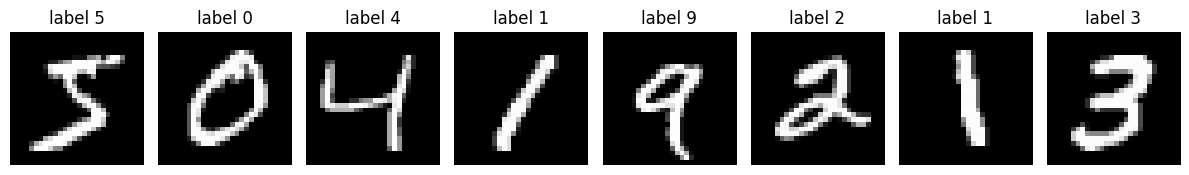

In [3]:
# A peek at the raw data
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, range(8)):
    img, label = train_full[i]
    ax.imshow(img.squeeze(0), cmap="gray")
    ax.set_title(f"label {label}")
    ax.axis("off")
fig.tight_layout()
plt.show()

## Model

Two convolutional blocks (`Conv -> ReLU -> MaxPool`) that shrink 28×28 down
to 7×7 while growing the channel count, then a small linear head producing
**one logit** (positive = "this is an 8"). Convolutions let nearby pixels
vote together, unlike the flat-vector MLPs from experiments 02–03 — that's
what lets the model learn *shape* rather than memorizing pixel positions.

In [4]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 28x28 -> 14x14
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 7 * 7, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )

    def forward(self, x):
        return self.classifier(self.features(x)).squeeze(1)


model = CNN().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"model: CNN, {n_params} parameters")

model: CNN, 26401 parameters


## Training loop

`BCEWithLogitsLoss` since this is binary (one logit), not a 10-way softmax.
Accuracy, precision, and recall are all tracked on validation — accuracy
alone can't tell us whether the model is actually finding 8s or just always
guessing "no".

In [5]:
def binary_labels(y):
    return (y == TARGET_DIGIT).float()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, n = 0.0, 0
    tp = fp = fn = tn = 0
    for x, y in loader:
        x = x.to(device)
        target = binary_labels(y).to(device)
        logits = model(x)
        total_loss += loss_fn(logits, target).item() * x.size(0)
        n += x.size(0)
        pred = (logits > 0).float()
        tp += ((pred == 1) & (target == 1)).sum().item()
        fp += ((pred == 1) & (target == 0)).sum().item()
        fn += ((pred == 0) & (target == 1)).sum().item()
        tn += ((pred == 0) & (target == 0)).sum().item()
    return {
        "loss": total_loss / n,
        "accuracy": (tp + tn) / n,
        "precision": tp / (tp + fp) if (tp + fp) else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
    }


loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 5
train_losses, val_losses, val_accuracies = [], [], []

for epoch in range(1, epochs + 1):
    model.train()
    running_loss, n_seen = 0.0, 0
    for x, y in train_loader:
        x = x.to(device)
        target = binary_labels(y).to(device)

        logits = model(x)
        loss = loss_fn(logits, target)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * x.size(0)
        n_seen += x.size(0)

    train_loss = running_loss / n_seen
    val_metrics = evaluate(model, val_loader, loss_fn)

    train_losses.append(train_loss)
    val_losses.append(val_metrics["loss"])
    val_accuracies.append(val_metrics["accuracy"])

    print(
        f"epoch {epoch} | train loss {train_loss:.4f} | val loss {val_metrics['loss']:.4f} "
        f"| val acc {val_metrics['accuracy']:.4f} | val precision {val_metrics['precision']:.4f} "
        f"| val recall {val_metrics['recall']:.4f}"
    )

epoch 1 | train loss 0.1450 | val loss 0.0579 | val acc 0.9822 | val precision 0.9109 | val recall 0.9127


epoch 2 | train loss 0.0481 | val loss 0.0437 | val acc 0.9858 | val precision 0.8972 | val recall 0.9702


epoch 3 | train loss 0.0341 | val loss 0.0239 | val acc 0.9922 | val precision 0.9814 | val recall 0.9405


epoch 4 | train loss 0.0264 | val loss 0.0248 | val acc 0.9920 | val precision 0.9915 | val recall 0.9286


epoch 5 | train loss 0.0227 | val loss 0.0268 | val acc 0.9914 | val precision 0.9978 | val recall 0.9167


## Results

In [6]:
test_metrics = evaluate(model, test_loader, loss_fn)
baseline_accuracy = (test_set.targets != TARGET_DIGIT).float().mean().item()

print(f"test accuracy:  {test_metrics['accuracy']:.4f}  (always-'not 8' baseline: {baseline_accuracy:.4f})")
print(f"test precision: {test_metrics['precision']:.4f}")
print(f"test recall:    {test_metrics['recall']:.4f}")

test accuracy:  0.9911  (always-'not 8' baseline: 0.9026)
test precision: 0.9933
test recall:    0.9148


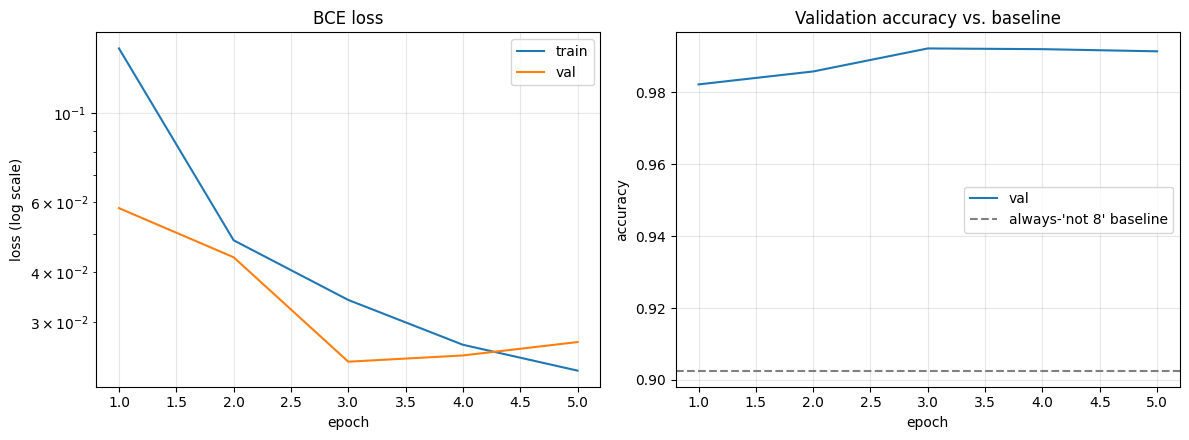

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(range(1, epochs + 1), train_losses, label="train")
axes[0].plot(range(1, epochs + 1), val_losses, label="val")
axes[0].set_yscale("log")
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("loss (log scale)")
axes[0].set_title("BCE loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(range(1, epochs + 1), val_accuracies, label="val")
axes[1].axhline(baseline_accuracy, color="gray", linestyle="--", label="always-'not 8' baseline")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("accuracy")
axes[1].set_title("Validation accuracy vs. baseline")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.tight_layout()
plt.show()

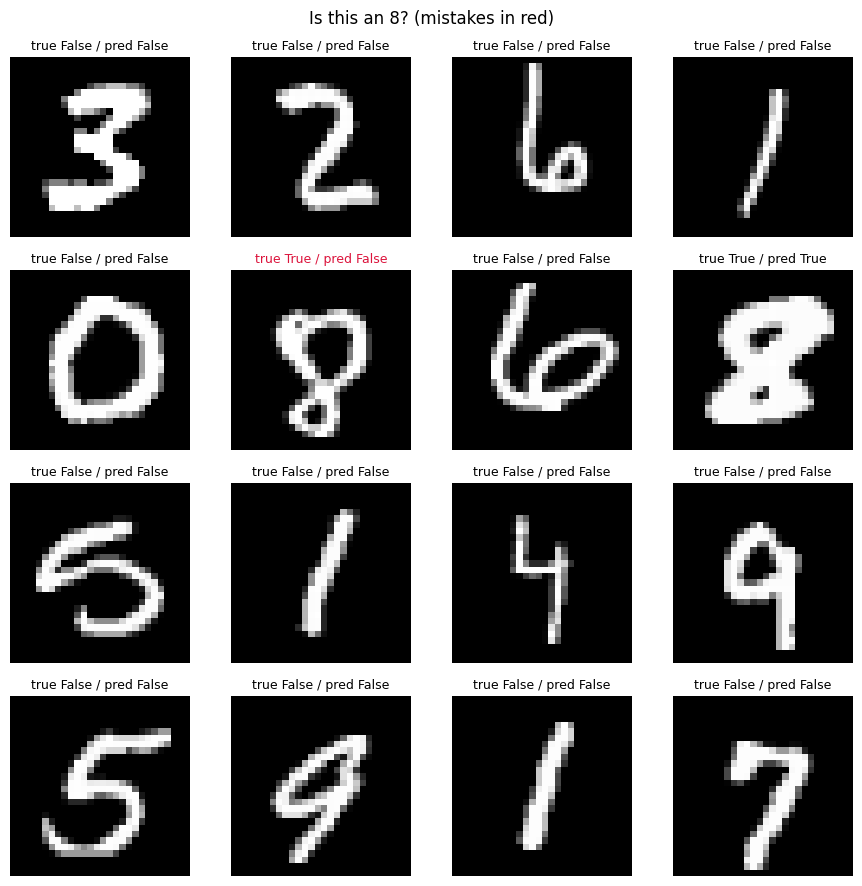

In [8]:
# Sample test predictions, mistakes highlighted in red
model.eval()
x_sample, y_sample = next(iter(DataLoader(test_set, batch_size=64, shuffle=True)))
with torch.no_grad():
    logits = model(x_sample.to(device))
    preds = (logits > 0).cpu().long()
true_is_8 = (y_sample == TARGET_DIGIT).long()

fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for i, ax in enumerate(axes.flat):
    correct = preds[i] == true_is_8[i]
    ax.imshow(x_sample[i, 0], cmap="gray")
    ax.set_title(
        f"true {bool(true_is_8[i])} / pred {bool(preds[i])}",
        fontsize=9, color="black" if correct else "crimson",
    )
    ax.axis("off")
fig.suptitle("Is this an 8? (mistakes in red)")
fig.tight_layout()
plt.show()

## Takeaways

- **Accuracy alone can lie.** With ~90% of MNIST *not* an 8, a model that
  never fires still scores ~90% "accuracy." Precision and recall show this
  model is actually finding 8s, not just refusing to guess.
- **Precision vs. recall trade off.** High precision means predicted-8s are
  almost always right; recall below 1.0 means some real 8s are still missed.
  Weighting the positive class in the loss (`pos_weight` in
  `nn.BCEWithLogitsLoss`) shifts that trade-off.
- **Convolutions vs. the earlier MLPs.** `Conv2d` slides a small learned
  filter across the image so nearby pixels vote together — that's what lets
  the model learn *shape* (the loop and crossbar of an 8) instead of
  memorizing individual pixel positions the way a flat-vector MLP would.

See `experiments/04_mnist_cnn_digit8/README.md` for the full writeup and
things to try next (e.g. `--pos-weight`, a harder digit pair).